# 05 — Thời tiết và AQI: có liên quan thế nào, sau khi bỏ chu kỳ mùa?

Notebook này trả lời **câu hỏi phụ 1** của đề tài (phần diễn giải, W9): thời tiết đi cùng AQI ra sao, theo từng thành phố. Nó dùng bảng đã ghép ở `04_weather_merge` và các quy ước của `03_eda`. Hàm dùng chung ở `src/corr_utils.py` (dùng lại `eda_utils.py`, không sửa file đó).

**Cách chạy:** *Kernel -> Restart & Run All*, từ thư mục `notebooks/`, sau khi đã chạy `01` và `04`. Hình lưu vào `reports/figures/` với tên `corr_01_*` đến `corr_04_*`.

## Câu hỏi nghiên cứu của đề tài

> **Thời tiết (gió, nhiệt độ, độ ẩm, mưa, lớp biên khí quyển) có liên quan thế nào tới các ngày ô nhiễm nặng (AQI ≥ 201) ở 8 thành phố Ấn Độ giai đoạn 2015–2020, và có giúp cảnh báo trước một ngày các ngày đó tốt hơn việc cho rằng "ngày mai giống hôm nay" không, để cơ quan môi trường và người dân có cảnh báo sức khỏe sớm hơn?**

Notebook này làm **câu phụ 1** (tương quan, W9). Câu phụ 2 (dự đoán AQI ngày mai, W10) và câu phụ 3 (cảnh báo ≥ 201, W11) làm ở các notebook sau.

## Ý chính của notebook: mùa là confounder lớn nhất

AQI và hầu hết các biến thời tiết đều có chu kỳ mùa rất mạnh (mùa đông: lạnh, khô, ô nhiễm nặng). Nếu chỉ tính tương quan thô, ta đo **chu kỳ mùa** nhiều hơn là ảnh hưởng của thời tiết. Vì vậy mọi kết luận chính ở đây là **trong cùng thành phố, cùng tháng**: một ngày được so với *ngày điển hình của tháng đó* (xem mục A).

## Quy ước (giữ đúng quy ước của `03_eda`, thêm các điểm riêng của phần này)

| Quy ước | Giá trị |
|---|---|
| Dữ liệu | `eda_utils.load()` (khoảng chung 14/06/2017 – 01/07/2020) + 6 biến thời tiết từ `weather_daily_8cities.csv` |
| Thời tiết | **Cùng ngày** với AQI (chưa phải dự báo). Dự báo ngày mai là việc của notebook 06 |
| Thành phố đủ ngày nặng | từ 100 ngày AQI ≥ 201 trở lên (đúng quy ước C1): Delhi, Lucknow, Gurugram, Jaipur, Amritsar. Ba thành phố còn lại chỉ mô tả, không kết luận về ngày nặng |
| Hệ số tương quan | **Spearman** (dữ liệu lệch phải, mưa phần lớn bằng 0) |
| Ngày kề nhau không độc lập | khoảng tin cậy và p-value tính bằng **bootstrap theo khối 14 ngày**; p-value công thức của Spearman và Mann-Whitney quá lạc quan nên chỉ để tham khảo |
| Nhiều phép thử | kiểm định giả thuyết: **Bonferroni**; bảng 48 hệ số tương quan: **FDR (Benjamini-Hochberg)** |
| Từ ngữ | "có liên quan", "đi cùng với". **Không** dùng "gây ra", "làm giảm" |

## 0. Setup

In [1]:
import sys, os
sys.path.append(os.path.abspath("../src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from corr_utils import (CITIES, ACCENT, NEUTRAL, WX, WX_LABEL, WX_SHORT, WX_UNIT, vn, set_style,
                        load_with_weather, core_cities, add_anomalies, spearman_by_city, corr_table,
                        tertile_in_strata, block_id, compare_groups, finish_chart, save_fig)

set_style()
eda, win, START, END = load_with_weather()
d = win.dropna(subset=["AQI"]).copy()                     # chỉ các ngày CÓ AQI, trong khoảng chung

core, n_heavy = core_cities(d)
core = sorted(core, key=lambda c: -n_heavy[c])            # nhiều ngày nặng nhất trước
others = [c for c in n_heavy.sort_values(ascending=False).index if c not in core]
order = core + others
print("Thành phố đủ ngày nặng (>= 100 ngày AQI >= 201):", {c: int(n_heavy[c]) for c in core})
print("Còn lại (chỉ mô tả):", {c: int(n_heavy[c]) for c in others})

Toàn bộ: 14.056 dòng, 01/01/2015 - 01/07/2020
Khoảng chung (biến win): 14/06/2017 - 01/07/2020, 8.912 dòng; 8.734 ngày có AQI
Thành phố đủ ngày nặng (>= 100 ngày AQI >= 201): {'Delhi': 564, 'Lucknow': 516, 'Gurugram': 495, 'Jaipur': 121, 'Amritsar': 117}
Còn lại (chỉ mô tả): {'Chennai': 34, 'Bengaluru': 2, 'Hyderabad': 1}


# Phần A — Tương quan thô chủ yếu là chu kỳ mùa

**Cách bỏ chu kỳ mùa.** Với mỗi cột (AQI và từng biến thời tiết), trừ đi **trung vị của cùng thành phố, cùng tháng**. Phần còn lại (cột có đuôi `_a`) cho biết *ngày đó cao hay thấp hơn một ngày điển hình của tháng ấy*. Tương quan của các cột `_a` là tương quan "trong cùng tháng".

**Cách tính độ chắc chắn.** Ngày kề nhau rất giống nhau (một đợt không khí tù đọng kéo dài nhiều ngày), nên 300 ngày không phải 300 quan sát độc lập. Khoảng tin cậy lấy bằng bootstrap theo khối 14 ngày liên tiếp; 48 hệ số (8 thành phố × 6 biến) được hiệu chỉnh FDR.

In [2]:
a = add_anomalies(d, ["AQI"] + WX)                         # cột *_a: lệch so với ngày điển hình cùng thành phố, cùng tháng

raw = spearman_by_city(d).loc[order]                       # tương quan thô
tab = corr_table(a)                                        # tương quan sau khi bỏ mùa, kèm CI bootstrap theo khối và FDR
adj = tab.pivot(index="City", columns="var", values="rho")[WX].loc[order]
sig = tab.pivot(index="City", columns="var", values="sig")[WX].loc[order]

print(f"{int(tab.sig.sum())}/{len(tab)} hệ số có khoảng tin cậy loại trừ 0 sau hiệu chỉnh FDR\n")
print("Spearman THÔ (AQI với thời tiết, cả năm):");  display(raw.round(2).rename(columns=WX_SHORT))
print("Spearman SAU KHI BỎ CHU KỲ MÙA (trong cùng thành phố, cùng tháng):"); display(adj.round(2).rename(columns=WX_SHORT))

32/48 hệ số có khoảng tin cậy loại trừ 0 sau hiệu chỉnh FDR

Spearman THÔ (AQI với thời tiết, cả năm):


,Nhiệt độ,Độ ẩm,Gió,Lớp biên,Mưa,Áp suất
Delhi,-0.52,-0.21,-0.12,-0.38,-0.52,0.63
Lucknow,-0.52,-0.29,-0.19,-0.28,-0.60,0.64
Gurugram,-0.33,-0.21,-0.12,-0.23,-0.40,0.43
Jaipur,-0.16,-0.43,-0.09,0.04,-0.49,0.35
Amritsar,-0.20,-0.20,-0.10,-0.19,-0.36,0.29
Chennai,-0.16,-0.13,-0.10,-0.02,-0.20,0.06
Bengaluru,0.02,-0.55,-0.43,-0.12,-0.43,0.48
Hyderabad,-0.34,-0.45,-0.52,-0.28,-0.56,0.63


Spearman SAU KHI BỎ CHU KỲ MÙA (trong cùng thành phố, cùng tháng):


var,Nhiệt độ,Độ ẩm,Gió,Lớp biên,Mưa,Áp suất
City,,,,,,
Delhi,0.23,-0.33,-0.18,0.08,-0.14,-0.16
Lucknow,0.23,-0.33,-0.07,0.13,-0.17,-0.20
Gurugram,0.21,-0.28,-0.11,0.09,-0.16,-0.10
Jaipur,0.32,-0.48,0.07,0.30,-0.27,-0.16
Amritsar,0.23,-0.26,-0.09,0.09,-0.19,-0.19
Chennai,-0.10,-0.14,-0.07,-0.04,-0.19,-0.05
Bengaluru,0.19,-0.31,-0.26,-0.05,-0.09,0.09
Hyderabad,0.10,-0.37,-0.26,-0.01,-0.17,-0.01


## Biểu đồ 1: bỏ chu kỳ mùa làm tương quan đổi hẳn

Đã lưu reports\figures\corr_01_raw_vs_adjusted.png


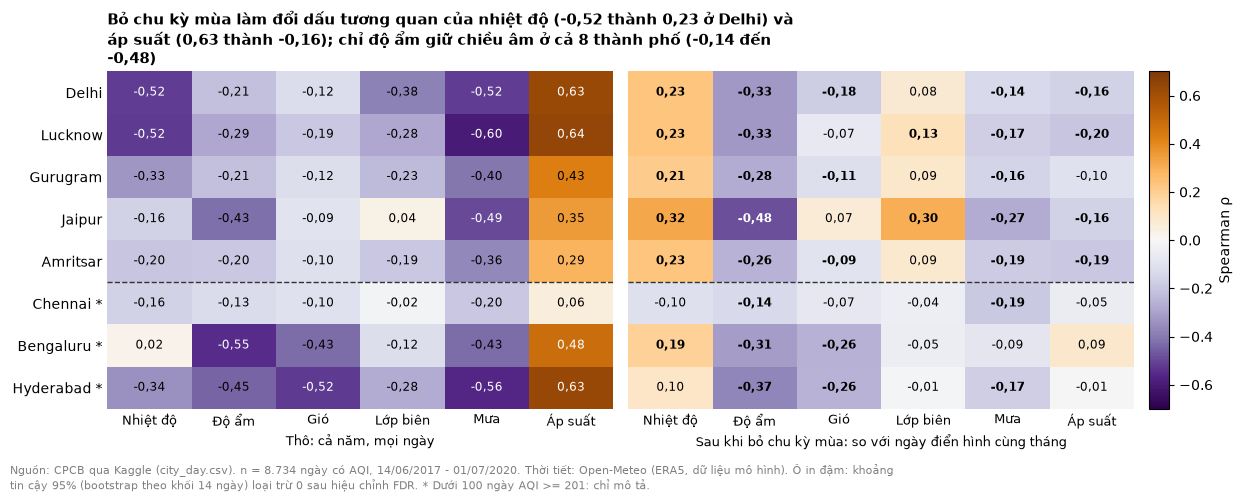

In [3]:
vmax = 0.7
fig, axes = plt.subplots(1, 3, figsize=(12.5, 5), gridspec_kw={"width_ratios": [1, 1, 0.04]})
panels = [(raw, None, "Thô: cả năm, mọi ngày"), (adj, sig, "Sau khi bỏ chu kỳ mùa: so với ngày điển hình cùng tháng")]
for ax, (m, s, name) in zip(axes[:2], panels):
    im = ax.imshow(m.values, cmap="PuOr_r", vmin=-vmax, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(WX))); ax.set_xticklabels([WX_SHORT[v] for v in WX], rotation=0, fontsize=9)
    ax.set_yticks(range(len(order))); ax.set_yticklabels([c + ("" if c in core else " *") for c in order] if ax is axes[0] else [""] * len(order))
    ax.tick_params(length=0); ax.set_xlabel(name, fontsize=9)
    for i, c in enumerate(order):
        for j, v in enumerate(WX):
            val = m.loc[c, v]; bold = s is not None and bool(s.loc[c, v])
            ax.text(j, i, vn(val, 2), ha="center", va="center", fontsize=8.5,
                    fontweight="bold" if bold else "normal", color="white" if abs(val) > 0.45 else "black")
    ax.axhline(len(core) - 0.5, color="#333333", lw=1, ls="--")
    for sp in ax.spines.values(): sp.set_visible(False)
fig.colorbar(im, cax=axes[2], label="Spearman ρ")

dl = "Delhi"
t_raw, t_adj = raw.loc[dl, "temp_mean"], adj.loc[dl, "temp_mean"]
p_raw, p_adj = raw.loc[dl, "pressure_mean"], adj.loc[dl, "pressure_mean"]
hum = adj["humidity_mean"]
assert t_raw < 0 < t_adj and p_raw > 0 > p_adj, "Dấu đã đổi: sửa tiêu đề và phần đọc kết quả"
assert (hum < 0).all() and sig["humidity_mean"].all(), "Độ ẩm không còn âm và có ý nghĩa ở cả 8 thành phố: sửa tiêu đề và phần đọc"
finish_chart(fig, axes[0],
             f"Bỏ chu kỳ mùa làm đổi dấu tương quan của nhiệt độ ({vn(t_raw, 2)} thành {vn(t_adj, 2)} ở Delhi) và áp suất "
             f"({vn(p_raw, 2)} thành {vn(p_adj, 2)}); chỉ độ ẩm giữ chiều âm ở cả 8 thành phố ({vn(hum.max(), 2)} đến {vn(hum.min(), 2)})",
             win, note="Ô in đậm: khoảng tin cậy 95% (bootstrap theo khối 14 ngày) loại trừ 0 sau hiệu chỉnh FDR. * Dưới 100 ngày AQI >= 201: chỉ mô tả.")
save_fig(fig, "01_raw_vs_adjusted")
plt.show()

### Đọc biểu đồ 1

- **Tương quan thô đo mùa nhiều hơn đo thời tiết.** Mùa đông vừa lạnh vừa khô vừa ô nhiễm, nên nhiệt độ thô tương quan *âm* với AQI. Khi chỉ so các ngày trong cùng tháng, chiều đổi thành *dương* (ngày ấm hơn thường lệ đi cùng AQI cao hơn thường lệ). Áp suất cũng đổi dấu. Đây là ví dụ rõ về confounder mùa.
- **Độ ẩm là biến duy nhất giữ nguyên chiều âm ở cả 8 thành phố**, và khoảng tin cậy loại trừ 0 ở cả 8 (ô in đậm).
- **Lớp biên khí quyển và gió yếu hơn nhiều so với kỳ vọng.** Lớp biên thô tương quan âm với AQI ở Delhi (−0,38), nhưng sau khi bỏ mùa gần như không còn (+0,08, khoảng tin cậy gồm 0), và dương rõ hơn ở Jaipur (+0,30). Điều này **ngược với trực giác** "lớp biên thấp thì ô nhiễm bị nén lại"; phần B kiểm tra riêng điều đó. Gió chỉ còn tương quan nhỏ và đổi dấu ở Jaipur.
- Ba thành phố cuối (ít ngày nặng) chỉ dùng để mô tả quan hệ với AQI nói chung, **không** dùng để nói về ngày nặng.

# Phần B — Kiểm định ba giả thuyết nêu trước (W9, năm bước)

Ba giả thuyết dưới đây xuất phát từ **cơ chế khí tượng đã biết** (gió phân tán, lớp biên thấp giữ ô nhiễm sát mặt đất, mưa rửa trôi), được chọn *không dựa vào* kết quả tương quan ở mục A. Độ ẩm và nhiệt độ **không** nằm trong danh sách này; chúng được xét ở phần C như phân tích **khám phá**.

| Bước | Nội dung |
|---|---|
| 1. H₀ / H₁ | H₀: trong cùng thành phố và cùng tháng, AQI của hai nhóm ngày không khác nhau. H₁: có khác (hai phía). Dự đoán chiều: **điều kiện bất lợi → AQI cao hơn** |
| | **H1:** gió yếu (tertile thấp của tốc độ gió) so với gió mạnh (tertile cao) · **H2:** lớp biên thấp so với cao · **H3:** ngày không mưa so với ngày mưa (≥ 1 mm) |
| 2. α | 0,05 chia cho số phép thử (3 giả thuyết × 5 thành phố = 15), tức **Bonferroni**: khoảng tin cậy 99,67% |
| 3. Phép thử | Tertile tính **trong từng (thành phố, tháng)** nên mỗi tháng đóng góp như nhau cho cả hai nhóm. Kết quả đo = AQI lệch so với ngày điển hình cùng tháng (`AQI_a`). Hiệu ứng = hiệu hai trung vị; khoảng tin cậy bootstrap theo khối 14 ngày; kèm xác suất vượt trội P(AQI nhóm bất lợi > nhóm thuận lợi) và Mann-Whitney (chỉ để tham khảo vì giả định độc lập bị vi phạm) |
| 4. Tính | Bảng bên dưới |
| 5. Kết luận | "Ủng hộ" nếu khoảng tin cậy nằm hẳn trên 0; "ngược chiều dự đoán" nếu nằm hẳn dưới 0; còn lại "chưa đủ bằng chứng" (**không** phải "không có ảnh hưởng") |

In [4]:
HYP = [("H1", "gió yếu − gió mạnh"), ("H2", "lớp biên thấp − cao"), ("H3", "không mưa − có mưa")]
M = len(core) * len(HYP)                                    # số phép thử, dùng cho hiệu chỉnh Bonferroni

rows = []
for c in core:
    x = a[a.City == c].copy(); x["blk"] = block_id(x)
    x["wind_t"] = tertile_in_strata(x, "wind_speed_mean"); x["blh_t"] = tertile_in_strata(x, "blh_mean")
    groups = {"H1": (x[x.wind_t == "thấp"], x[x.wind_t == "cao"]),
              "H2": (x[x.blh_t == "thấp"], x[x.blh_t == "cao"]),
              "H3": (x[~x.rain_day], x[x.rain_day])}
    for h, (g1, g2) in groups.items():                      # g1: điều kiện bất lợi, g2: điều kiện thuận lợi
        rows.append({"City": c, "H": h, **compare_groups(g1.AQI_a.to_numpy(), g1.blk.to_numpy(),
                                                          g2.AQI_a.to_numpy(), g2.blk.to_numpy(), m_tests=M)})
tests = pd.DataFrame(rows)
tests["ket_luan"] = np.where(tests.ci_lo > 0, "ủng hộ", np.where(tests.ci_hi < 0, "ngược chiều dự đoán", "chưa đủ bằng chứng"))

show = tests.assign(**{"hiệu ứng (điểm AQI)": tests.hieu_ung.round(1),
                       "CI 99,67%": "[" + tests.ci_lo.round(1).astype(str) + "; " + tests.ci_hi.round(1).astype(str) + "]",
                       "P(vượt trội)": tests.p_ps.round(2), "p Mann-Whitney (tham khảo)": tests.p_MW.round(3)}
                   ).rename(columns={"City": "Thành phố", "H": "GT", "n_batloi": "n bất lợi", "n_thuanloi": "n thuận lợi", "ket_luan": "kết luận"})
display(show[["Thành phố", "GT", "n bất lợi", "n thuận lợi", "hiệu ứng (điểm AQI)", "CI 99,67%", "P(vượt trội)",
              "p Mann-Whitney (tham khảo)", "kết luận"]].set_index(["Thành phố", "GT"]))
print(tests.ket_luan.value_counts().to_dict())

n bất lợi  n thuận lợi  hiệu ứng (điểm AQI)       CI 99,67%  \
Thành phố GT                                                                
Delhi     H1        371          367                 30.0     [9.6; 50.2]   
          H2        371          367                 -5.5   [-35.5; 17.2]   
          H3        827          278                  9.5    [-2.2; 29.9]   
Lucknow   H1        372          370                  6.0    [-7.9; 23.5]   
          H2        372          370                -10.5    [-28.2; 4.0]   
          H3        792          319                 11.5    [-2.8; 24.2]   
Gurugram  H1        361          356                 15.0    [-5.5; 41.8]   
          H2        361          356                 -8.5   [-39.8; 10.5]   
          H3        811          259                 12.0    [-3.7; 34.2]   
Jaipur    H1        366          365                 -4.5    [-16.5; 7.7]   
          H2        366          365                -25.0  [-41.3; -11.0]   
          H3        869          224                 17.2     [7.0; 30.0]   
Amritsar  H1        348          341                  6.8    [-3.2; 19.9]   
          H2        348          341                -11.0    [-26.4; 7.0]   
          H3        750          279                 16.0     [3.5; 27.8]   

              P(vượt trội)  p Mann-Whitney (tham khảo)             kết luận  
Thành phố GT                                                                 
Delhi     H1          0.63                       0.000               ủng hộ  
          H2          0.46                       0.073   chưa đủ bằng chứng  
          H3          0.56                       0.002   chưa đủ bằng chứng  
Lucknow   H1          0.55                       0.017   chưa đủ bằng chứng  
          H2          0.44                       0.006   chưa đủ bằng chứng  
          H3          0.55                       0.006   chưa đủ bằng chứng  
Gurugram  H1          0.58                       0.000   chưa đủ bằng chứng  
          H2          0.47                       0.108   chưa đủ bằng chứng  
          H3          0.54                       0.032   chưa đủ bằng chứng  
Jaipur    H1          0.48                       0.447   chưa đủ bằng chứng  
          H2          0.33                       0.000  ngược chiều dự đoán  
          H3          0.64                       0.000               ủng hộ  
Amritsar  H1          0.56                       0.008   chưa đủ bằng chứng  
          H2          0.46                       0.071   chưa đủ bằng chứng  
          H3          0.60                       0.000               ủng hộ

{'chưa đủ bằng chứng': 11, 'ủng hộ': 3, 'ngược chiều dự đoán': 1}


## Biểu đồ 2: chỉ vài trong 15 so sánh cho kết luận rõ

Đã lưu reports\figures\corr_02_hypothesis_tests.png


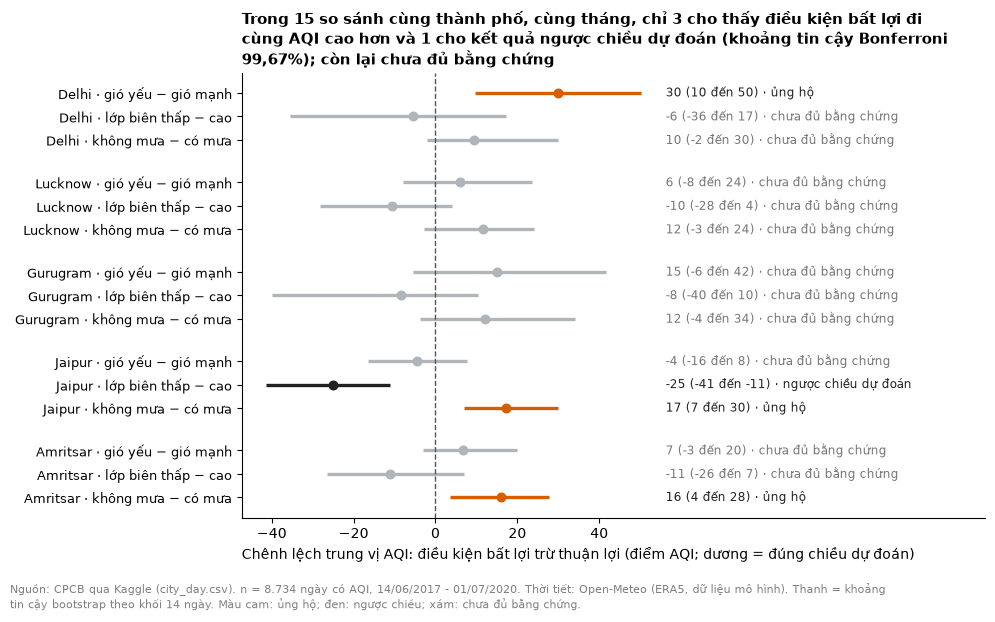

In [5]:
t = tests.set_index(["City", "H"]).loc[[(c, h) for c in core for h, _ in HYP]].reset_index()
short = dict(HYP)
ypos, yy = [], 0.0
for r in t.itertuples():
    ypos.append(yy); yy += 1
    if r.H == "H3": yy += 0.8                               # khoảng trống giữa các thành phố
colr = {"ủng hộ": ACCENT, "ngược chiều dự đoán": "#222222", "chưa đủ bằng chứng": NEUTRAL}

fig, ax = plt.subplots(figsize=(10, 6.2))
xmax = t.ci_hi.max() + 4
for y_, r in zip(ypos, t.itertuples()):
    ax.plot([r.ci_lo, r.ci_hi], [y_, y_], color=colr[r.ket_luan], lw=2.4, solid_capstyle="butt")
    ax.scatter(r.hieu_ung, y_, color=colr[r.ket_luan], s=38, zorder=3)
    ax.text(xmax + 2, y_, f"{vn(r.hieu_ung, 0)} ({vn(r.ci_lo, 0)} đến {vn(r.ci_hi, 0)}) · {r.ket_luan}", va="center", fontsize=8.5,
            color="#222222" if r.ket_luan != "chưa đủ bằng chứng" else "#777777")
ax.axvline(0, color="#555555", lw=1, ls="--")
ax.set_yticks(ypos); ax.set_yticklabels([f"{r.City} · {short[r.H]}" for r in t.itertuples()], fontsize=9)
ax.invert_yaxis(); ax.set_xlim(t.ci_lo.min() - 6, xmax + 80)
ax.set_xticks(np.arange(-40, xmax, 20))
ax.set_xlabel("Chênh lệch trung vị AQI: điều kiện bất lợi trừ thuận lợi (điểm AQI; dương = đúng chiều dự đoán)", loc="left")
vc = tests.ket_luan.value_counts()
n_ok, n_rev = int(vc.get("ủng hộ", 0)), int(vc.get("ngược chiều dự đoán", 0))
finish_chart(fig, ax, f"Trong {M} so sánh cùng thành phố, cùng tháng, chỉ {n_ok} cho thấy điều kiện bất lợi đi cùng AQI cao hơn và {n_rev} cho kết quả "
                      f"ngược chiều dự đoán (khoảng tin cậy Bonferroni 99,67%); còn lại chưa đủ bằng chứng", win,
             note="Thanh = khoảng tin cậy bootstrap theo khối 14 ngày. Màu cam: ủng hộ; đen: ngược chiều; xám: chưa đủ bằng chứng.")
save_fig(fig, "02_hypothesis_tests")
plt.show()

### Đọc biểu đồ 2

- **Không có kết luận chung cho mọi thành phố.** Chỉ có 3 phép ủng hộ: gió yếu ở Delhi, và ngày không mưa ở Jaipur và Amritsar. Phần lớn các phép còn lại có khoảng tin cậy rộng, chứa 0: *chưa đủ bằng chứng*, không có nghĩa là không có ảnh hưởng.
- **Một kết quả ngược chiều dự đoán:** ở Jaipur, ngày lớp biên *thấp* có AQI *thấp hơn* ngày lớp biên cao (cùng tháng). Một giả thuyết (không kiểm được ở đây): Jaipur là thành phố nhiều bụi, ngày nóng khô nhiều gió có lớp biên cao nhưng bụi lại được nâng lên. Đừng viết thành kết luận.
- **p-value công thức và khoảng tin cậy bootstrap có thể mâu thuẫn.** Ví dụ Gurugram, gió yếu so với mạnh: p Mann-Whitney rất nhỏ, nhưng khoảng tin cậy theo khối vẫn chứa 0. Lý do: ngày kề nhau giống nhau nên số "quan sát độc lập" ít hơn nhiều so với số dòng. Vì vậy kết luận dựa vào **khoảng tin cậy theo khối**, không dựa vào p-value công thức.
- Delhi và Gurugram có thời tiết gần như trùng nhau (tương quan theo ngày 0,95–0,999, xem `04_weather_merge`), nên **không** đếm kết quả của hai nơi này là hai bằng chứng độc lập.

# Phần C — Độ ẩm: biến đi cùng AQI nhất quán nhất (phân tích khám phá)

Ở mục A, độ ẩm nổi lên **sau khi nhìn kết quả**, nên phần này là **khám phá**: nó gợi ý một giả thuyết cho dữ liệu khác hoặc cho mô hình dự đoán, chưa phải kết luận đã kiểm định trước. Biến "mạnh nhất" được chọn bằng code (trung vị của |ρ| sau khi bỏ mùa, qua 5 thành phố đủ ngày nặng), không chọn tay.

In [6]:
strength = (tab[tab.City.isin(core)].groupby("var").rho.apply(lambda s: s.abs().median()).sort_values(ascending=False))
top = strength.index[0]
print("Trung vị |ρ| sau khi bỏ mùa, 5 thành phố đủ ngày nặng:"); display(strength.round(2).rename(index=WX_LABEL).to_frame("|ρ|"))
assert top == "humidity_mean", f"Biến mạnh nhất không còn là độ ẩm ({top}): sửa phần C"

Trung vị |ρ| sau khi bỏ mùa, 5 thành phố đủ ngày nặng:


,|ρ|
var,
Độ ẩm TB,0.33
Nhiệt độ TB,0.23
Lượng mưa,0.17
Áp suất,0.16
Lớp biên khí quyển TB,0.09
Tốc độ gió TB,0.09


## Biểu đồ 3: dose-response (nhóm 1 = khô hơn thường lệ nhất, nhóm 10 = ẩm nhất)

Đã lưu reports\figures\corr_03_humidity_deciles.png


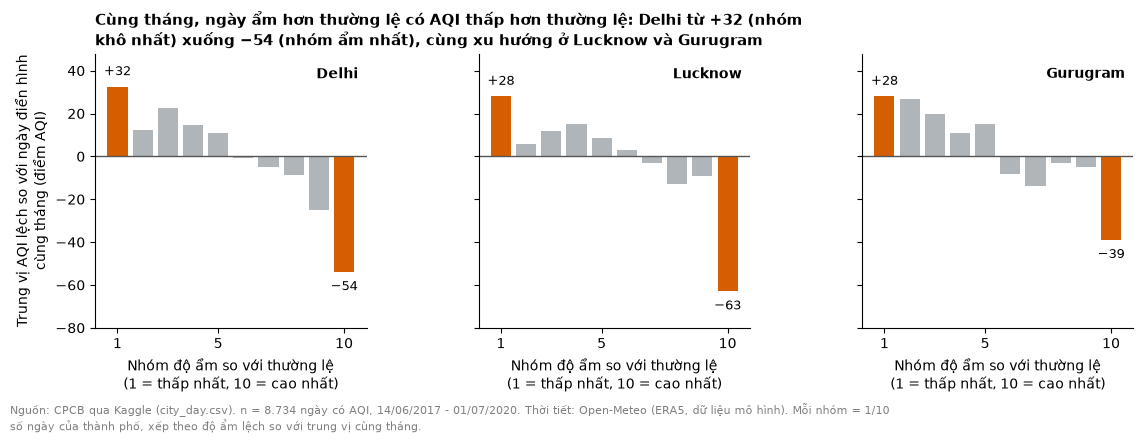

In [7]:
three = core[:3]
fig, axes = plt.subplots(1, 3, figsize=(11.5, 4.4), sharey=True)
dec = {}
for ax, c in zip(axes, three):
    x = a[a.City == c]
    g = pd.qcut(x[top + "_a"].rank(method="first"), 10, labels=False) + 1      # 1 = thấp nhất so với thường lệ
    m = x.groupby(g).AQI_a.median(); dec[c] = m
    ax.bar(m.index, m.values, color=[ACCENT if k in (1, 10) else NEUTRAL for k in m.index])
    for k in (1, 10):
        ax.text(k, m[k] + (4 if m[k] >= 0 else -4), f"{m[k]:+.0f}".replace("-", "−"), ha="center", va="bottom" if m[k] >= 0 else "top", fontsize=9)
    ax.axhline(0, color="#555555", lw=1)
    ax.text(0.97, 0.95, c, transform=ax.transAxes, ha="right", va="top", fontsize=10, fontweight="bold")
    ax.set_xticks([1, 5, 10]); ax.set_ylim(-80, 48)
    ax.set_xlabel(f"Nhóm {WX_SHORT[top].lower()} so với thường lệ\n(1 = thấp nhất, 10 = cao nhất)")
axes[0].set_ylabel("Trung vị AQI lệch so với ngày điển hình\ncùng tháng (điểm AQI)")
d1, d10 = dec["Delhi"][1], dec["Delhi"][10]
assert d1 > 0 > d10 and all(dec[c][1] > dec[c][10] for c in three), "Dose-response không còn giảm: sửa tiêu đề"
finish_chart(fig, axes[0], f"Cùng tháng, ngày ẩm hơn thường lệ có AQI thấp hơn thường lệ: Delhi từ {d1:+.0f} (nhóm khô nhất) xuống {d10:+.0f} (nhóm ẩm nhất), "
                           f"cùng xu hướng ở Lucknow và Gurugram".replace("-", "−"), win,
             note="Mỗi nhóm = 1/10 số ngày của thành phố, xếp theo độ ẩm lệch so với trung vị cùng tháng.")
save_fig(fig, "03_humidity_deciles")
plt.show()

## Biểu đồ 4: tỉ lệ ngày AQI ≥ 201 theo nhóm độ ẩm trong cùng tháng

t,ẩm thấp,ẩm vừa,ẩm cao
Delhi,64,50,38
Lucknow,53,52,34
Gurugram,57,46,36
Jaipur,19,9,4
Amritsar,12,12,10


Đã lưu reports\figures\corr_04_poor_share_by_humidity.png


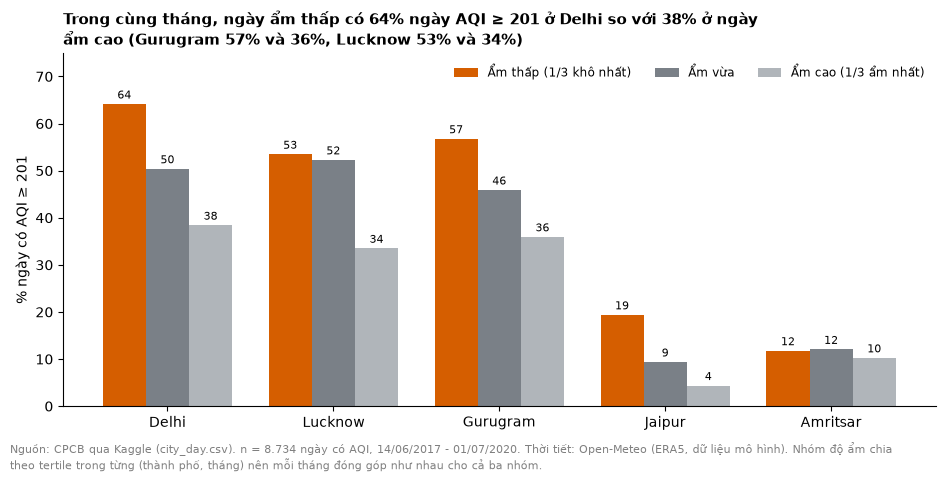

In [8]:
labels3 = ["thấp", "giữa", "cao"]
share = {}
for c in core:
    x = a[a.City == c].copy(); x["t"] = tertile_in_strata(x, top)
    share[c] = x.groupby("t").poor.mean().reindex(labels3) * 100
sh = pd.DataFrame(share).T                                   # hàng: thành phố; cột: nhóm độ ẩm
display(sh.round(0).rename(columns={"thấp": "ẩm thấp", "giữa": "ẩm vừa", "cao": "ẩm cao"}).astype(int))

fig, ax = plt.subplots(figsize=(9.5, 4.8))
w_, xs = 0.26, np.arange(len(core))
for k, (g, cc, nm) in enumerate(zip(labels3, [ACCENT, "#7A8087", NEUTRAL], ["Ẩm thấp (1/3 khô nhất)", "Ẩm vừa", "Ẩm cao (1/3 ẩm nhất)"])):
    b = ax.bar(xs + (k - 1) * w_, sh[g].values, w_, color=cc, label=nm)
    ax.bar_label(b, labels=[vn(v) for v in sh[g].values], padding=2, fontsize=8)
ax.set_xticks(xs); ax.set_xticklabels(core); ax.set_ylim(0, 75)
ax.set_ylabel("% ngày có AQI ≥ 201"); ax.legend(frameon=False, ncol=3, fontsize=8.5, loc="upper right")
dl_, gu_, lu_ = sh.loc["Delhi"], sh.loc["Gurugram"], sh.loc["Lucknow"]
assert all(sh.loc[c, "thấp"] > sh.loc[c, "cao"] for c in ["Delhi", "Gurugram", "Lucknow"]), "Chiều đã đổi: sửa tiêu đề"
finish_chart(fig, ax, f"Trong cùng tháng, ngày ẩm thấp có {vn(dl_['thấp'])}% ngày AQI ≥ 201 ở Delhi so với {vn(dl_['cao'])}% ở ngày ẩm cao "
                      f"(Gurugram {vn(gu_['thấp'])}% và {vn(gu_['cao'])}%, Lucknow {vn(lu_['thấp'])}% và {vn(lu_['cao'])}%)", win,
             note="Nhóm độ ẩm chia theo tertile trong từng (thành phố, tháng) nên mỗi tháng đóng góp như nhau cho cả ba nhóm.")
save_fig(fig, "04_poor_share_by_humidity")
plt.show()

### Đọc biểu đồ 3 và 4

- Ở Delhi, Gurugram và Lucknow, AQI **giảm gần như đều** khi độ ẩm (so với thường lệ của tháng) tăng, và dốc nhất ở nhóm ẩm nhất (có thể là ngày mưa, sương mù hoặc mây dày). Quan hệ không chỉ nằm ở hai đầu.
- Với người ra quyết định: trong cùng một tháng, ngày khô hơn thường lệ có xác suất AQI ≥ 201 cao hơn rõ rệt ở ba thành phố nặng nhất. Ở Amritsar chênh lệch gần như không có, ở Jaipur nhỏ (tỉ lệ nền thấp).
- **Chỉ là đi cùng với.** Độ ẩm cao có thể đại diện cho mưa, sương mù, mây hoặc một khối không khí khác. Mục D kiểm tra riêng khả năng "chỉ do mưa".

# Phần D — Kiểm tra độ nhạy (cho câu vấn đáp "nếu đổi cách làm, kết luận có đổi không?")

Bốn cách, trên 5 thành phố đủ ngày nặng:
1. **Cách bỏ mùa khác:** trung vị theo *tuần trong năm* thay vì theo tháng (bớt sót chu kỳ trong tháng).
2. **Bỏ ngẫu nhiên 10% số ngày**, lặp 200 lần (câu vấn đáp W8).
3. **Bỏ các ngày mưa** (≥ 1 mm), để xem độ ẩm có chỉ là "ngày mưa" không.
4. Cách gốc (theo tháng, mọi ngày), làm mốc.

In [9]:
aw = add_anomalies(d, ["AQI"] + WX, base="week")
rho_m = adj.loc[core]
rho_w = spearman_by_city(aw, suffix="_a").loc[core]
rho_nr = spearman_by_city(a[~a.rain_day], suffix="_a").loc[core]

rng = np.random.default_rng(42)
lo10, hi10 = pd.DataFrame(index=core, columns=WX, dtype=float), pd.DataFrame(index=core, columns=WX, dtype=float)
for c in core:
    g = a[a.City == c]
    vals = {v: [] for v in WX}
    for _ in range(200):
        s = g.sample(frac=0.9, random_state=int(rng.integers(1e9)))
        for v in WX:
            vals[v].append(s.AQI_a.corr(s[v + "_a"], method="spearman"))
    for v in WX:
        lo10.loc[c, v], hi10.loc[c, v] = min(vals[v]), max(vals[v])

rows = []
for v in WX:
    allv = pd.concat([rho_m[v], rho_w[v], rho_nr[v], lo10[v], hi10[v]], axis=1)
    keep_sign = (np.sign(allv).eq(np.sign(rho_m[v]), axis=0)).all(axis=1)
    rows.append({"biến": WX_SHORT[v], "ρ gốc (trung vị 5 TP)": rho_m[v].median(), "nhỏ nhất qua các cách": allv.min().min(),
                 "lớn nhất qua các cách": allv.max().max(), "TP không đổi dấu khi đổi cách làm": f"{int(keep_sign.sum())}/{len(core)}"})
sens = pd.DataFrame(rows).set_index("biến").round(2)
display(sens)
print("Chi tiết độ ẩm theo thành phố (gốc | bỏ mùa theo tuần | bỏ ngày mưa | bỏ 10% nhỏ nhất, lớn nhất):")
display(pd.DataFrame({"gốc": rho_m["humidity_mean"], "tuần": rho_w["humidity_mean"], "không mưa": rho_nr["humidity_mean"],
                      "bỏ10% min": lo10["humidity_mean"], "bỏ10% max": hi10["humidity_mean"]}).round(2))

,ρ gốc (trung vị 5 TP),nhỏ nhất qua các cách,lớn nhất qua các cách,TP không đổi dấu khi đổi cách làm
biến,,,,
Nhiệt độ,0.23,0.17,0.41,5/5
Độ ẩm,-0.33,-0.51,-0.17,5/5
Gió,-0.09,-0.21,0.09,5/5
Lớp biên,0.09,0.02,0.32,5/5
Mưa,-0.17,-0.30,-0.06,5/5
Áp suất,-0.16,-0.31,-0.07,5/5


Chi tiết độ ẩm theo thành phố (gốc | bỏ mùa theo tuần | bỏ ngày mưa | bỏ 10% nhỏ nhất, lớn nhất):


,gốc,tuần,không mưa,bỏ10% min,bỏ10% max
Delhi,-0.33,-0.33,-0.26,-0.35,-0.31
Lucknow,-0.33,-0.31,-0.27,-0.35,-0.29
Gurugram,-0.28,-0.29,-0.28,-0.30,-0.25
Jaipur,-0.48,-0.48,-0.46,-0.51,-0.46
Amritsar,-0.26,-0.27,-0.17,-0.28,-0.23


### Đọc kết quả độ nhạy

- **Độ ẩm** âm ở cả 5 thành phố qua cả 4 cách (ρ từ −0,51 đến −0,17), kể cả khi bỏ hết ngày mưa (yếu đi chút ít, ví dụ Delhi −0,33 thành −0,26): nó không chỉ là hiệu ứng "ngày mưa".
- **Nhiệt độ** dương ở cả 5 thành phố nhưng **độ lớn phụ thuộc cách bỏ mùa** (ρ từ 0,17 đến 0,41; bỏ theo tuần cho hệ số lớn hơn theo tháng). Chỉ nên nói về chiều, không nói về độ lớn.
- **Áp suất và mưa** giữ dấu âm nhưng hệ số nhỏ (ρ −0,31 đến −0,06).
- **Gió** (trung vị ρ −0,09) **không cùng dấu giữa các thành phố** (dương ở Jaipur); **lớp biên** dương và nhỏ ở bốn thành phố (0,08 đến 0,13), 0,30 ở Jaipur. Cả hai yếu và không nên dùng làm căn cứ chính. Cột "giữ nguyên dấu" ở bảng trên chỉ nói mỗi thành phố không đổi dấu khi đổi cách làm, không nói các thành phố cùng dấu với nhau.

# Tổng hợp

## Phát hiện (mỗi ý gắn một biểu đồ)

| # | Phát hiện (có con số) | Biểu đồ | Confounder có thể | Hạn chế |
|---|---|---|---|---|
| D1 | Tương quan thô giữa AQI và thời tiết chủ yếu là chu kỳ mùa: ở Delhi, nhiệt độ từ −0,52 thành +0,23 và áp suất từ +0,63 thành −0,16 sau khi chỉ so các ngày trong cùng tháng; lớp biên khí quyển từ −0,38 thành +0,08 (khoảng tin cậy gồm 0). Độ ẩm là biến duy nhất giữ chiều âm ở cả 8 thành phố (−0,14 đến −0,48). | 1 | **Mùa** (đã bỏ bằng trung vị cùng tháng); nguồn phát thải theo mùa (đốt rơm rạ, sưởi) không có trong dữ liệu | Bỏ mùa theo tháng còn sót chu kỳ trong tháng (đầu tháng 11 khác cuối tháng 11); độ lớn hệ số của nhiệt độ và áp suất phụ thuộc cách bỏ mùa, chỉ dùng chiều |
| D2 | Trong 15 so sánh nêu trước (3 giả thuyết × 5 thành phố, cùng tháng), 3 cho kết quả đúng chiều dự đoán sau hiệu chỉnh Bonferroni: gió yếu ở Delhi (AQI cao hơn khoảng 30 điểm, khoảng tin cậy 10 đến 50), ngày không mưa ở Jaipur (khoảng 17, từ 7 đến 30) và Amritsar (16, từ 4 đến 28). 1 ngược chiều: lớp biên thấp ở Jaipur có AQI thấp hơn khoảng 25 điểm (−41 đến −11). 11 chưa đủ bằng chứng. | 2 | Mùa (đã cân bằng bằng tertile trong từng tháng); thành phố nhiều bụi (Jaipur) | Xác suất vượt trội chỉ khoảng 0,5-0,6: hiệu ứng nhỏ so với dao động hằng ngày. Ngày kề nhau không độc lập nên dùng bootstrap theo khối. Delhi và Gurugram không phải hai bằng chứng độc lập |
| D3 | Trong cùng tháng, ngày ẩm thấp có 64% ngày AQI ≥ 201 ở Delhi so với 38% ngày ẩm cao (Gurugram 57% và 36%, Lucknow 53% và 34%, Jaipur 19% và 4%); Amritsar gần như không đổi (12% và 10%). AQI lệch so với thường lệ giảm từ +32 (nhóm khô nhất) xuống −54 (ẩm nhất) ở Delhi. | 3, 4 | Độ ẩm có thể đại diện cho mưa, sương mù, mây hay khối không khí; đã thử bỏ ngày mưa, vẫn giữ chiều | Phân tích khám phá (độ ẩm được chọn sau khi xem kết quả), cần kiểm lại trên dữ liệu chưa dùng (tập test ở notebook 06). Độ ẩm là số mô hình, không phải số đo tại trạm |

## Hạn chế (mỗi ý gắn với kết luận mà nó đe dọa)

- **Thời tiết cùng ngày, không phải dự báo** (D1–D3): kết quả mô tả quan hệ cùng ngày; chưa nói gì về dự báo trước một ngày (việc của notebook 06).
- **Ngày nặng nằm ở ba thành phố** (D2, D3): ba thành phố miền Nam gần như không có ngày nặng, nên phần ngày nặng chỉ nói về 5 thành phố phía bắc.
- **AQI mùa đông ở Delhi, Gurugram, Lucknow có trung vị 300–400, gần trần thang 500** (D2): chênh lệch giữa các nhóm bị nén, nên hiệu ứng thực có thể lớn hơn số đo.
- **Dữ liệu thời tiết là mô hình lưới 0,25° (khoảng 25 km)** (D1–D3), một điểm cho mỗi thành phố, trong khi AQI là trung bình các trạm.

## Câu vấn đáp đã công bố trước: "confounder hợp lý là gì?"

Trả lời cho phần này: **mùa** là confounder chung (cùng lúc làm lạnh, khô và ô nhiễm), đã xử lý bằng cách so các ngày trong cùng thành phố, cùng tháng. Còn lại: nguồn phát thải đổi theo mùa (đốt rơm rạ, sưởi, giao thông) không có trong dữ liệu; sương mù và mưa có thể đứng sau độ ẩm; Delhi và Gurugram chung thời tiết nên không độc lập.

## Việc tiếp theo cho notebook 06 (dự đoán AQI ngày mai)

- **Độ ẩm và nhiệt độ** mang thông tin trong-tháng, nên là biến ứng viên chính. **Gió và lớp biên** yếu, nhưng vẫn thử.
- Kỳ vọng thực tế: AQI hôm nay đã chứa phần lớn thông tin về AQI ngày mai, nên thêm thời tiết nhiều khả năng chỉ cải thiện **vừa phải**. Đó vẫn là kết quả đáng báo cáo.
- Kết luận ở phần C cần được **kiểm lại trên tập test theo thời gian**, vì độ ẩm được chọn sau khi xem dữ liệu.

## Kiểm tra lại các con số trong bảng phát hiện

In [10]:
r2 = lambda x: round(float(x), 2)
assert (r2(raw.loc["Delhi", "temp_mean"]), r2(adj.loc["Delhi", "temp_mean"])) == (-0.52, 0.23)
assert (r2(raw.loc["Delhi", "pressure_mean"]), r2(adj.loc["Delhi", "pressure_mean"])) == (0.63, -0.16)
assert (r2(raw.loc["Delhi", "blh_mean"]), r2(adj.loc["Delhi", "blh_mean"])) == (-0.38, 0.08)
ci_blh = tab[(tab.City == "Delhi") & (tab["var"] == "blh_mean")].iloc[0]
assert ci_blh.lo < 0 < ci_blh.hi
assert (r2(adj["humidity_mean"].max()), r2(adj["humidity_mean"].min())) == (-0.14, -0.48)

T = tests.set_index(["City", "H"])
def chk(c, h, eff, lo, hi):
    r = T.loc[(c, h)]
    assert round(r.hieu_ung) == eff and round(r.ci_lo) == lo and round(r.ci_hi) == hi, (c, h, r.hieu_ung, r.ci_lo, r.ci_hi)
chk("Delhi", "H1", 30, 10, 50); chk("Jaipur", "H3", 17, 7, 30); chk("Amritsar", "H3", 16, 4, 28); chk("Jaipur", "H2", -25, -41, -11)
assert tests.ket_luan.value_counts().to_dict() == {"chưa đủ bằng chứng": 11, "ủng hộ": 3, "ngược chiều dự đoán": 1}
assert tests.p_ps.between(0.3, 0.7).all()

pct = sh.round(0)
assert (pct.loc["Delhi", "thấp"], pct.loc["Delhi", "cao"], pct.loc["Gurugram", "thấp"], pct.loc["Gurugram", "cao"]) == (64, 38, 57, 36)
assert (pct.loc["Lucknow", "thấp"], pct.loc["Lucknow", "cao"], pct.loc["Jaipur", "thấp"], pct.loc["Jaipur", "cao"]) == (53, 34, 19, 4)
assert (pct.loc["Amritsar", "thấp"], pct.loc["Amritsar", "cao"]) == (12, 10)
assert (round(dec["Delhi"][1]), round(dec["Delhi"][10])) == (32, -54)
assert sens.loc["Độ ẩm", "TP không đổi dấu khi đổi cách làm"] == "5/5"
print("Mọi con số trong bảng phát hiện khớp với kết quả vừa tính")

Mọi con số trong bảng phát hiện khớp với kết quả vừa tính
